# Kalman Filter for GPS + IMU Position Tracking

We extend the 2-state Kalman filter from the altitude notebook to 4 states: East/North position and East/North velocity. The IMU (accelerometer + orientation) predicts how the car moves between GPS fixes, and the GPS (1 Hz) corrects the position. Press `shift + enter` to run each cell.

Before we can run the filter, we have to get the accelerometer readings into the same East/North frame as the GPS, and line up the GPS and IMU timestamps. Both turn out to be more interesting than expected!

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import utils

## Settings

In [2]:
# Recordings (folders containing imu.csv, gps.csv and meta.json)
DRIVE_1_PATH = "recordings/drive_1"   # used for exploring and tuning
DRIVE_2_PATH = "recordings/drive_2"   # used for evaluation
DRIVE_3_PATH = "recordings/drive_3"
DRIVE_4_PATH = "recordings/drive_4"

# Time parked at the start of each recording, used for the gravity reference
REF_TIME_S = 10.0

# Noise std devs measured from the static recording
SIGMA_A_REST = 0.03   # accelerometer, horizontal axes (m/s²)
SIGMA_GPS = 2.0       # GPS position (m); a starting guess, see "GPS noise" below

# GPS fixes describe the moment ~1 s before they arrive (see "GPS timing")
GPS_LAG_S = 1.0

# Only trust GPS course above this speed (it's meaningless when stopped)
MIN_SPEED_MPS = 4.0

# How quickly the GPS course corrects the IMU heading (s)
HEADING_TAU_S = 2.0

# Draw OpenStreetMap tiles under the tracks (needs contextily + internet)
BASEMAP = True

## Look at the Data

We load the recording and convert latitude/longitude to East/North metres around the first GPS fix (flat-earth approximation, plenty accurate over a few km). The filter works entirely in metres; we only convert back to latitude/longitude to draw the map.

GPS also reports speed and course (direction of travel, clockwise from north), measured from the Doppler shift of the satellite signals. We turn these into an East/North velocity, which makes a handy reference for the filter's velocity estimate (like the differentiated barometer in the altitude notebook).

In [3]:
def load_drive(path, gps_lag=GPS_LAG_S, verbose=True):
    # Load a recording, convert GPS to local East/North metres around the
    # first fix, and shift GPS times back by gps_lag (see "GPS timing")
    imu, gps, meta = utils.load_imu_gps(path)

    # Drop IMU rows logged before the first orientation sample
    keep = ~np.isnan(imu["qr"])
    imu = {k: v[keep] for k, v in imu.items()}

    # Keep GPS rows with a position fix
    fix = ~np.isnan(gps["lat_deg"])
    lat, lon = gps["lat_deg"][fix], gps["lon_deg"][fix]
    origin = (lat[0], lon[0])
    east, north = utils.lla_to_en(lat, lon, *origin)

    # GPS (Doppler) velocity from speed and course (clockwise from north)
    speed = gps["speed_mps"][fix]
    course = np.radians(gps["course_deg"][fix])

    d = {
        "name": Path(path).name,
        "t_imu": imu["t"],
        "acc": np.column_stack([imu["ax"], imu["ay"], imu["az"]]),
        "R": utils.quat_to_rotmat(imu["qi"], imu["qj"], imu["qk"], imu["qr"]),
        "rv_status": imu["rv_status"],
        "t_gps_arrival": gps["t"][fix],
        "t_gps": gps["t"][fix] - gps_lag,
        "east": east,
        "north": north,
        "speed": speed,
        "course": course,
        "v_east": speed * np.sin(course),
        "v_north": speed * np.cos(course),
        "origin": origin,
    }

    if verbose:
        t = d["t_imu"]
        print(f"{d['name']}: {t[-1] - t[0]:.1f} s")
        print(f"  IMU samples: {len(t)} ({(len(t) - 1) / (t[-1] - t[0]):.1f} Hz)")
        print(f"  GPS fixes: {len(east)} of {len(gps['t'])} rows")
        print(f"  Track: {np.ptp(east):.0f} m E-W x {np.ptp(north):.0f} m N-S, "
              f"max speed {np.nanmax(speed):.1f} m/s")
    return d

drive_1: 300.0 s
  IMU samples: 37327 (124.4 Hz)
  GPS fixes: 300 of 300 rows
  Track: 837 m E-W x 1125 m N-S, max speed 22.4 m/s


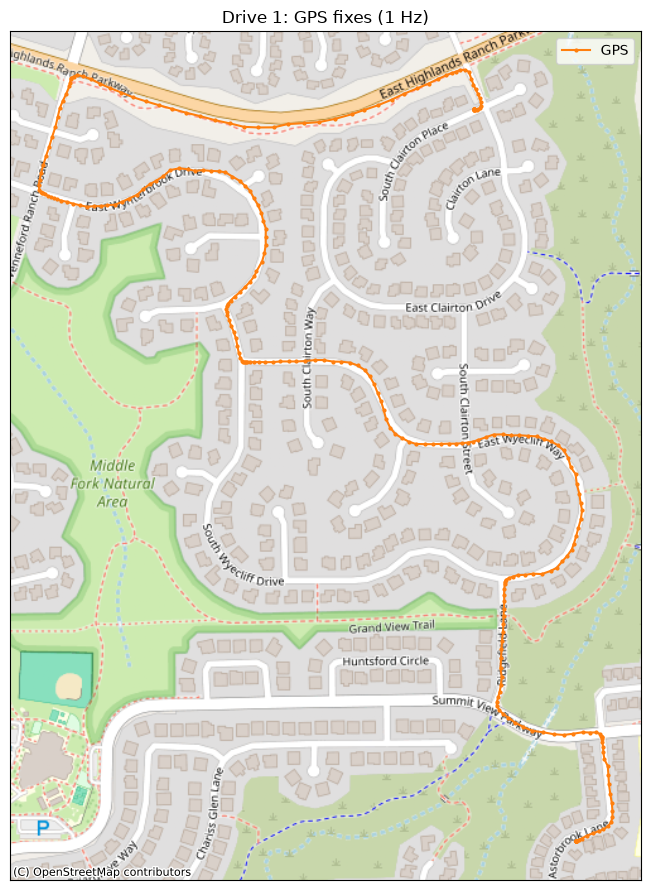

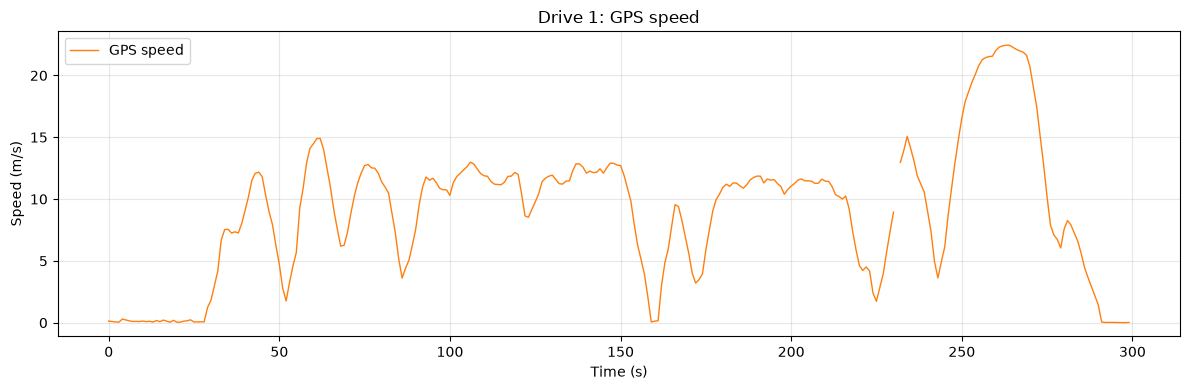

In [5]:
drive = load_drive(DRIVE_1_PATH)

# GPS track on the map
utils.plot_tracks(
    [(drive["east"], drive["north"], "GPS", {"color": "tab:orange", "marker": ".", "ms": 4})],
    drive["origin"], title="Drive 1: GPS fixes (1 Hz)", basemap=BASEMAP,
)

# Speed over time
utils.plot_traces(
    [(drive["t_gps"], drive["speed"], "GPS speed", {"color": "tab:orange"})],
    "Speed (m/s)", title="Drive 1: GPS speed",
)

## GPS Timing

The GPS row's `t_us` is when the NMEA sentences arrived, but the fix describes an earlier moment. The PA1010D outputs each fix just as the *next* PPS pulse fires, so the fix is roughly 1 s old when it arrives (plus a bit of processing time). At 15 m/s, a 1 s timing error is a 15 m position error, so this matters!

To measure the lag, we compare how fast the car turns according to each sensor:

* **IMU**: change in heading between consecutive orientation samples (yaw rate). This works no matter how the board is mounted.
* **GPS**: change in course between fixes

We slide the GPS data back in time and look for the shift where the two agree best.

In [6]:
def imu_relative_heading(d):
    # Heading (rad, clockwise) relative to the first sample, from the change in
    # orientation between consecutive samples. Works for any mounting.
    R = d["R"]
    dR = np.einsum("nij,nkj->nik", R[1:], R[:-1])      # R_k R_(k-1)^T
    d_yaw = -np.arctan2(dR[:, 1, 0], dR[:, 0, 0])      # clockwise positive
    return np.concatenate([[0.0], np.cumsum(d_yaw)])


def turn_rate_correlation(d, lags, min_speed=MIN_SPEED_MPS):
    # Correlation between IMU and GPS turn rates for each candidate GPS lag
    heading = imu_relative_heading(d)
    ok = ~np.isnan(d["course"])
    t_gps = d["t_gps_arrival"][ok]
    gps_rate = np.gradient(np.unwrap(d["course"][ok]), t_gps)
    moving = d["speed"][ok] > min_speed

    corr = []
    for lag in lags:
        t_fix = t_gps - lag
        imu_rate = np.gradient(np.interp(t_fix, d["t_imu"], heading), t_fix)
        corr.append(np.corrcoef(imu_rate[moving], gps_rate[moving])[0, 1])
    return np.array(corr)

Best lag: 1.10 s (correlation 0.883)
Using GPS_LAG_S = 1.0 s


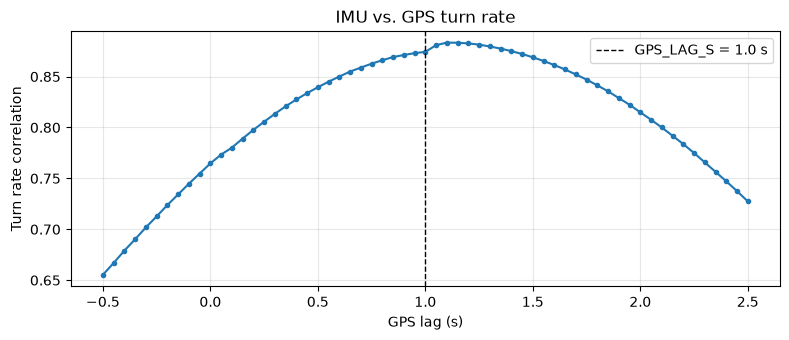

In [7]:
lags = np.arange(-0.5, 2.51, 0.05)
corr = turn_rate_correlation(drive, lags)
best_lag = lags[np.argmax(corr)]
print(f"Best lag: {best_lag:.2f} s (correlation {corr.max():.3f})")
print(f"Using GPS_LAG_S = {GPS_LAG_S} s")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lags, corr, ".-")
ax.axvline(GPS_LAG_S, color="k", ls="--", lw=1, label=f"GPS_LAG_S = {GPS_LAG_S} s")
ax.set_xlabel("GPS lag (s)")
ax.set_ylabel("Turn rate correlation")
ax.set_title("IMU vs. GPS turn rate")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

The peak is broad, so we round to 1 s, which matches how the receiver works. (The PPS timestamps in the log would pin this down exactly, if the PPS pin is wired up and working.)

## From the Sensor Frame to East/North

The accelerometer measures in the sensor's own frame (x, y, z axes of the board), but the GPS measures East/North. Our plan was to rotate each acceleration sample into the world frame using the BNO085's orientation quaternion, then subtract gravity.

### Why not just use the BNO085 orientation?

In a car, that orientation turns out to be unreliable:

* **Heading**: the BNO085 references heading to magnetic north, and a car is a big metal box with motors and wiring. The magnetometer never finished calibrating (`rv_status` stays at 0), and the heading wanders by tens of degrees.
* **Tilt**: the BNO085 estimates "down" partly from the accelerometer, so it mistakes the car speeding up, braking, and turning for the board tilting.

Let's compare the BNO085's heading of the car with the GPS course. We need to know which way the board faces in the car to do this, which we work out in the next section.

### Step 1: Mount calibration (sensor frame → car frame)

The board is taped down, so the car's forward/left/up directions are fixed directions in the sensor frame. We find them once per recording:

* **Up**: while parked, the accelerometer only measures gravity. As in the altitude notebook, we also subtract this reference reading from every sample, which removes gravity and the accelerometer bias.
* **Forward**: the car only speeds up and slows down along its forward axis, so we find the horizontal sensor direction whose acceleration best matches the change in GPS speed (least squares).
* **Left**: up × forward

Then the forward and lateral (left) accelerations are just dot products with these directions. No orientation estimate needed!

> Hills: on a slope, part of gravity leaks into the forward axis (a 5% grade adds ~0.5 m/s²). We tried correcting this with the BNO085 pitch and with GPS altitude, but both made it worse, so the filter has to treat it as noise. GPS corrections stop it from building up.

In [8]:
def calibrate_mount(d, ref_time=REF_TIME_S, min_speed=3.0):
    # Find the car's up/forward/left directions in the sensor frame
    t, acc = d["t_imu"], d["acc"]

    # Gravity reference: average while parked (also removes accelerometer bias)
    g_ref = acc[t < t[0] + ref_time].mean(axis=0)
    up = g_ref / np.linalg.norm(g_ref)

    # Two horizontal directions in the sensor frame (perpendicular to up)
    helper = np.eye(3)[np.argmin(np.abs(up))]
    h1 = np.cross(up, helper)
    h1 /= np.linalg.norm(h1)
    h2 = np.cross(up, h1)

    # GPS acceleration along the road (change in speed)
    dspeed = np.gradient(d["speed"], d["t_gps"])
    ok = (d["speed"] > min_speed) & ~np.isnan(dspeed)

    # Horizontal sensor acceleration, averaged over 1 s around each GPS fix
    a_h = utils.window_average(t, (acc - g_ref) @ np.column_stack([h1, h2]), d["t_gps"])

    # Which horizontal direction best explains the speed changes?
    c, *_ = np.linalg.lstsq(a_h[ok], dspeed[ok], rcond=None)
    fwd = c[0] * h1 + c[1] * h2
    fwd /= np.linalg.norm(fwd)
    left = np.cross(up, fwd)

    return {"g_ref": g_ref, "up": up, "fwd": fwd, "left": left}


def car_frame_acc(d, mount):
    # Forward and left acceleration (m/s²), gravity and bias removed
    a = d["acc"] - mount["g_ref"]
    return a @ mount["fwd"], a @ mount["left"]

Sensor frame directions:  up [0.128 0.026 0.991]  forward [-0.004 -1.     0.026]  left [ 0.992 -0.007 -0.128]
Board tilt from level: 7.5 deg


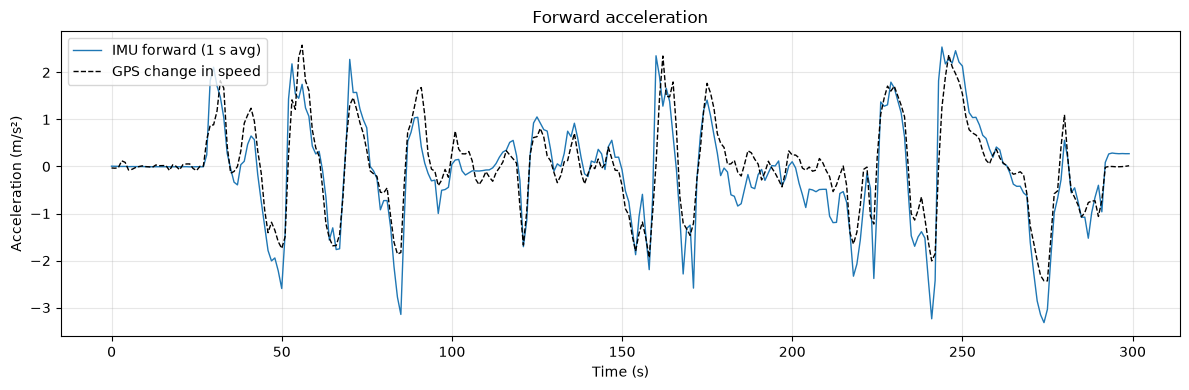

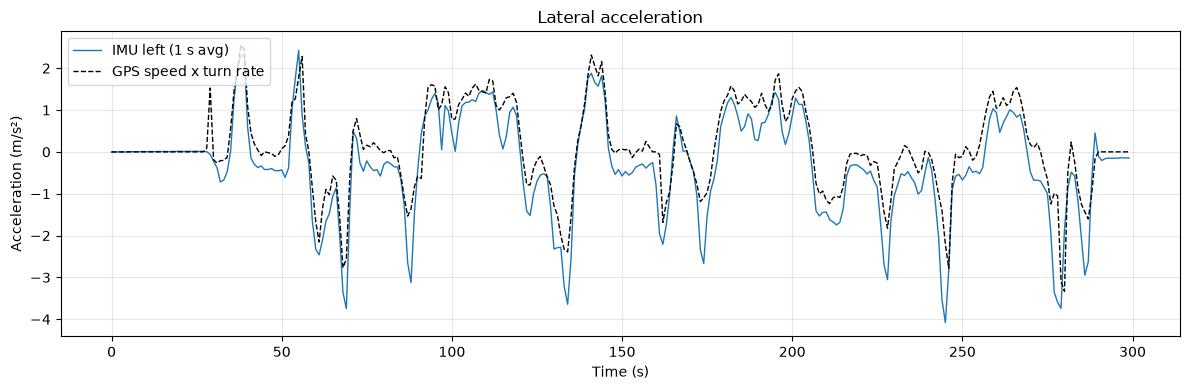

In [9]:
mount = calibrate_mount(drive)
np.set_printoptions(precision=3, suppress=True)
print(f"Sensor frame directions:  up {mount['up']}  forward {mount['fwd']}  left {mount['left']}")
tilt = np.degrees(np.arccos(mount["up"][2]))
print(f"Board tilt from level: {tilt:.1f} deg")

a_fwd, a_left = car_frame_acc(drive, mount)

# Compare with GPS: change in speed, and centripetal acceleration (speed x turn rate)
ok = ~np.isnan(drive["course"])
t_g = drive["t_gps"][ok]
dspeed = np.gradient(drive["speed"][ok], t_g)
a_centripetal = -drive["speed"][ok] * np.gradient(np.unwrap(drive["course"][ok]), t_g)

utils.plot_traces(
    [(t_g, utils.window_average(drive["t_imu"], a_fwd, t_g), "IMU forward (1 s avg)", {"color": "tab:blue"}),
     (t_g, dspeed, "GPS change in speed", {"color": "k", "ls": "--"})],
    "Acceleration (m/s²)", title="Forward acceleration",
)
utils.plot_traces(
    [(t_g, utils.window_average(drive["t_imu"], a_left, t_g), "IMU left (1 s avg)", {"color": "tab:blue"}),
     (t_g, a_centripetal, "GPS speed x turn rate", {"color": "k", "ls": "--"})],
    "Acceleration (m/s²)", title="Lateral acceleration",
)

Now we can compare the BNO085 heading of the car (the direction its forward axis points) with the GPS course, and check how well each approach predicts the change in speed:

Magnetometer calibration status (rv_status) counts: {0: 37327}


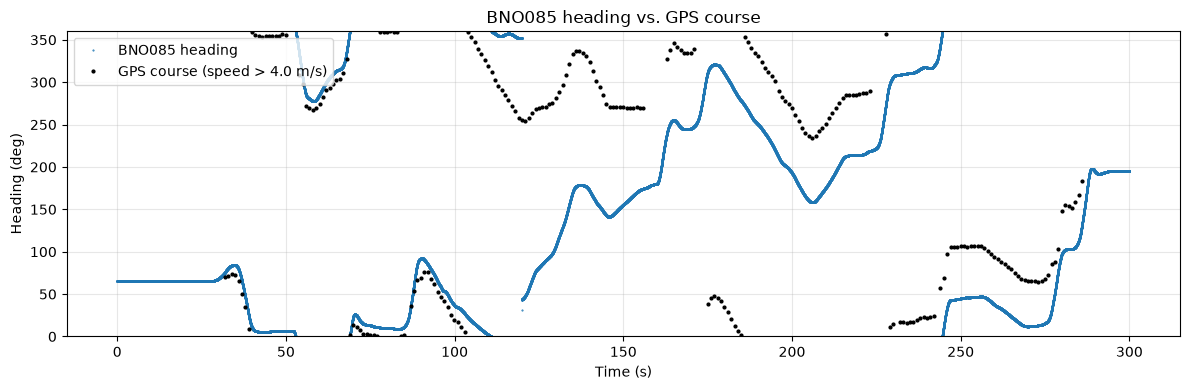

Forward acceleration from car frame (mount calibration) : correlation with GPS 0.92
Forward acceleration from BNO085 world frame            : correlation with GPS 0.34


In [10]:
def imu_heading(d, mount):
    # Heading (rad, clockwise from north) of the car's forward axis according
    # to the BNO085 orientation
    fwd_world = d["R"] @ mount["fwd"]
    return np.unwrap(np.arctan2(fwd_world[:, 0], fwd_world[:, 1]))


heading = imu_heading(drive, mount)
moving = drive["speed"] > MIN_SPEED_MPS
status, counts = np.unique(drive["rv_status"], return_counts=True)
print("Magnetometer calibration status (rv_status) counts:",
      {int(s): int(c) for s, c in zip(status, counts)})

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(drive["t_imu"], np.degrees(heading) % 360, ".", ms=1, label="BNO085 heading")
ax.plot(drive["t_gps"][moving], np.degrees(drive["course"][moving]), ".", color="k", ms=4,
        label=f"GPS course (speed > {MIN_SPEED_MPS} m/s)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Heading (deg)")
ax.set_ylim(0, 360)
ax.set_title("BNO085 heading vs. GPS course")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Forward acceleration two ways: car frame vs. BNO085 world frame projected
# onto the GPS course
t_imu = drive["t_imu"]
a_world = np.einsum("nij,nj->ni", drive["R"], drive["acc"])
a_world -= a_world[t_imu < t_imu[0] + REF_TIME_S].mean(axis=0)
course_imu = np.interp(t_imu, t_g, np.unwrap(drive["course"][ok]))
a_fwd_world = a_world[:, 0] * np.sin(course_imu) + a_world[:, 1] * np.cos(course_imu)

m = drive["speed"][ok] > 3.0
for label, a in (("car frame (mount calibration)", a_fwd),
                 ("BNO085 world frame", a_fwd_world)):
    a_avg = utils.window_average(t_imu, a, t_g)
    print(f"Forward acceleration from {label:30s}: "
          f"correlation with GPS {np.corrcoef(a_avg[m], dspeed[m])[0, 1]:.2f}")

### Step 2: Heading (car frame → East/North)

We still need the car's heading to rotate forward/left acceleration into East/North. Look closely at the plot above: the BNO085 heading has the right *shape* (its turns line up with the GPS course), but its offset drifts, and sometimes swings wildly when the magnetometer recalibrates. The gyroscope is doing a good job of tracking *changes* in heading; it's the absolute reference that's bad.

So we keep the BNO085's heading changes and fix the offset with the GPS course:

* Whenever the car is moving faster than `MIN_SPEED_MPS`, compute the heading error (GPS course − BNO085 heading)
* Smooth the error with a low-pass filter (time constant `HEADING_TAU_S`) and add it to the BNO085 heading
* When the car is slow or GPS is missing, hold the last correction

It only uses GPS fixes from the past, so it works in real time (and during GPS outages, it can't cheat).

> This is a separate little estimator bolted onto our linear filter. The "proper" fix is to put heading into the Kalman filter state, which makes the motion model non-linear: that's what an extended Kalman filter (EKF) is for!

In [11]:
def heading_correction(d, heading, gps_available=None, tau=HEADING_TAU_S,
                       min_speed=MIN_SPEED_MPS):
    # Low-pass filtered heading error (GPS course - IMU heading), updated only
    # from GPS fixes where the car is moving. Returns the corrected heading
    # (rad) at each IMU sample.
    if gps_available is None:
        gps_available = np.ones(len(d["t_gps"]), dtype=bool)
    t_gps = d["t_gps"]
    err = utils.wrap_angle(d["course"] - np.interp(t_gps, d["t_imu"], heading))
    use = gps_available & (d["speed"] > min_speed) & ~np.isnan(err)

    # Average the error as a unit vector so it wraps cleanly at +/-180 deg
    corr = np.zeros(len(t_gps))
    z = None
    t_prev = None
    for k in range(len(t_gps)):
        if use[k]:
            e = np.exp(1j * err[k])
            if z is None:
                z = e
            else:
                alpha = 1.0 - np.exp(-(t_gps[k] - t_prev) / tau)
                z = z + alpha * (e - z)
            t_prev = t_gps[k]
        corr[k] = np.angle(z) if z is not None else 0.0

    # Hold each correction until the next GPS fix
    idx = np.searchsorted(t_gps, d["t_imu"], side="right") - 1
    corr_imu = np.where(idx >= 0, corr[np.clip(idx, 0, None)], 0.0)
    return heading + corr_imu


def imu_to_east_north(d, mount, gps_available=None):
    # East/North acceleration (m/s²) at each IMU sample, and the heading used
    a_fwd, a_left = car_frame_acc(d, mount)
    psi = heading_correction(d, imu_heading(d, mount), gps_available)

    # Forward points along psi; left points along psi - 90 deg
    a_east = a_fwd * np.sin(psi) - a_left * np.cos(psi)
    a_north = a_fwd * np.cos(psi) + a_left * np.sin(psi)
    return a_east, a_north, psi

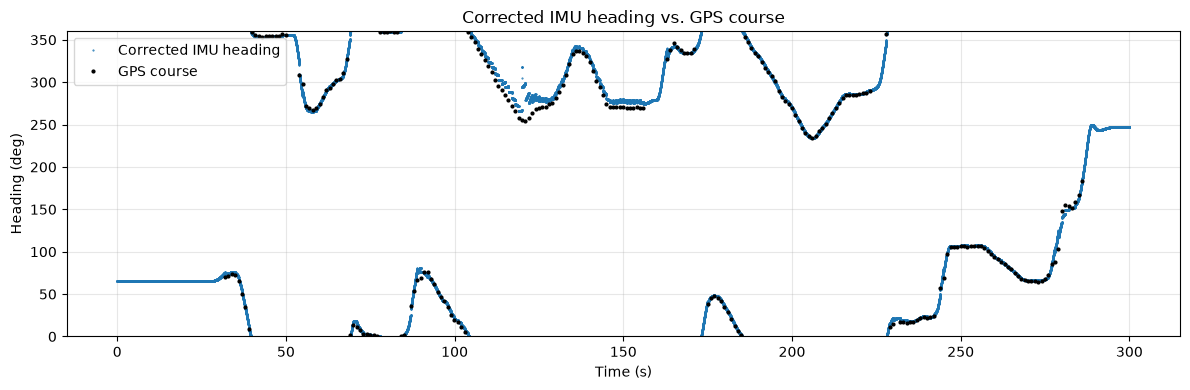

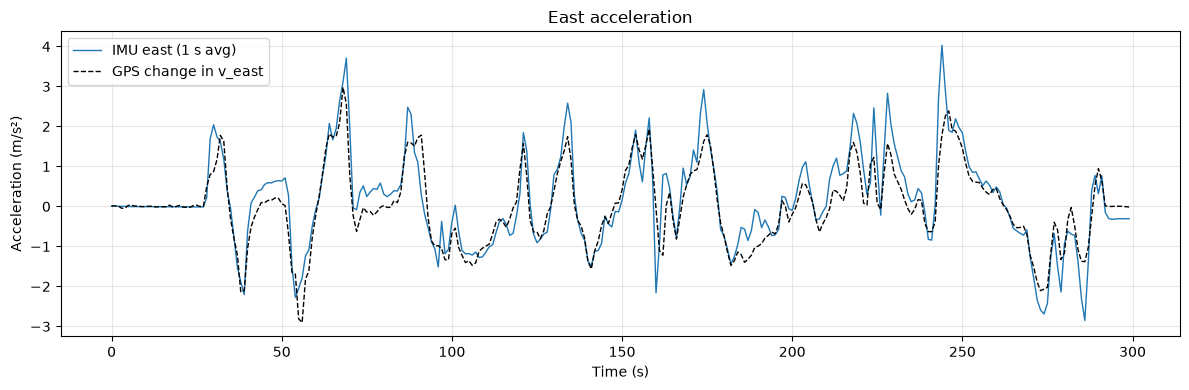

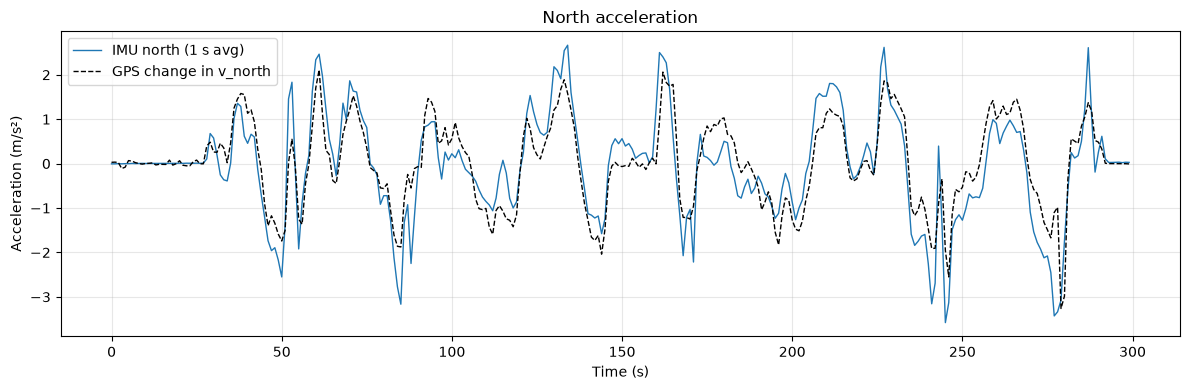

In [12]:
a_east, a_north, psi = imu_to_east_north(drive, mount)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(drive["t_imu"], np.degrees(psi) % 360, ".", ms=1, label="Corrected IMU heading")
ax.plot(drive["t_gps"][moving], np.degrees(drive["course"][moving]), ".", color="k", ms=4,
        label="GPS course")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Heading (deg)")
ax.set_ylim(0, 360)
ax.set_title("Corrected IMU heading vs. GPS course")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# East/North acceleration vs. GPS (change in Doppler velocity)
okv = ~np.isnan(drive["v_east"])
t_v = drive["t_gps"][okv]
for comp, a in (("east", a_east), ("north", a_north)):
    utils.plot_traces(
        [(t_v, utils.window_average(drive["t_imu"], a, t_v), f"IMU {comp} (1 s avg)", {"color": "tab:blue"}),
         (t_v, np.gradient(drive[f"v_{comp}"][okv], t_v), f"GPS change in v_{comp}", {"color": "k", "ls": "--"})],
        "Acceleration (m/s²)", title=f"{comp.capitalize()} acceleration",
    )

## Naive Estimates

Before building the filter, let's look at what each sensor gives us on its own:

* **GPS only**: accurate in the long run, but only once per second. Connecting the dots cuts corners, and there's nothing between fixes.
* **IMU only (dead reckoning)**: integrate acceleration twice, starting parked at the first fix. Smooth and fast, but every small error in acceleration grows into a velocity error, which grows into a position error...

Dead reckoning is 7648 m off after 300 s


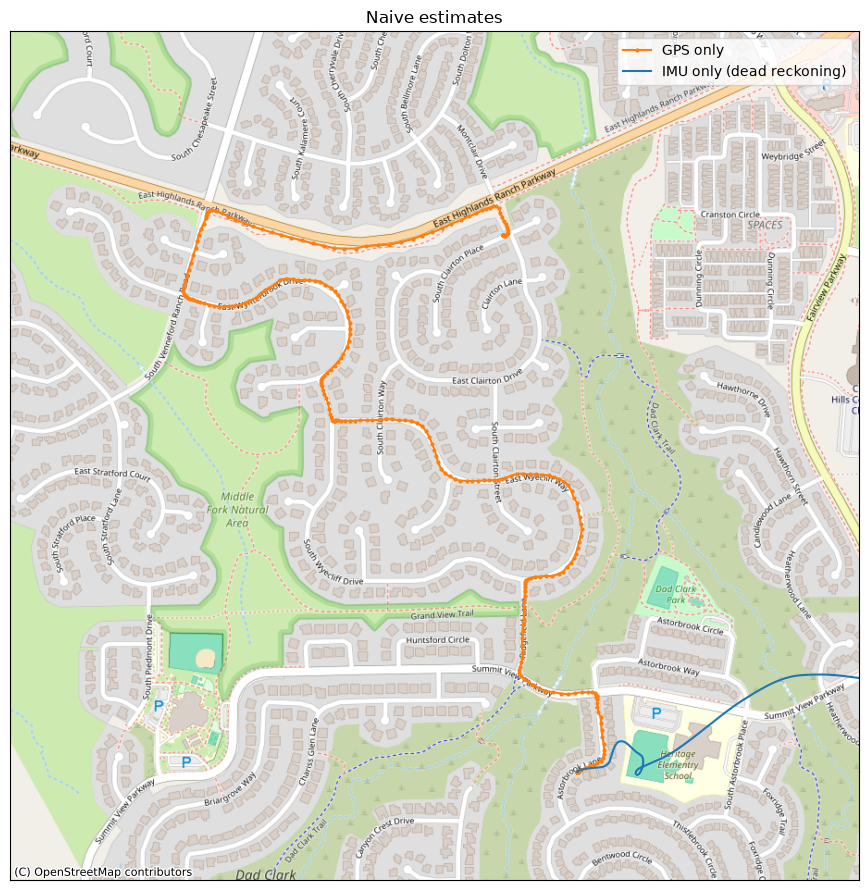

In [13]:
def dead_reckon(t, a_east, a_north, p0=(0.0, 0.0), v0=(0.0, 0.0)):
    # Integrate East/North acceleration twice (same as the altitude notebook,
    # once per axis)
    p = np.zeros((len(t), 2))
    v = np.zeros((len(t), 2))
    p[0], v[0] = p0, v0
    a = np.column_stack([a_east, a_north])
    for k in range(1, len(t)):
        dt = t[k] - t[k - 1]
        v[k] = v[k - 1] + a[k - 1] * dt
        p[k] = p[k - 1] + v[k - 1] * dt + 0.5 * a[k - 1] * dt**2
    return p, v


p_dr, v_dr = dead_reckon(drive["t_imu"], a_east, a_north,
                         p0=(drive["east"][0], drive["north"][0]))
t_end = drive["t_imu"][-1]
drift = np.hypot(p_dr[-1, 0] - drive["east"][-1], p_dr[-1, 1] - drive["north"][-1])
print(f"Dead reckoning is {drift:.0f} m off after {t_end:.0f} s")

# Keep the GPS track in view (dead reckoning wanders far away)
center = (np.mean(drive["east"]), np.mean(drive["north"]))
half = 0.75 * max(np.ptp(drive["east"]), np.ptp(drive["north"]))
utils.plot_tracks(
    [(drive["east"], drive["north"], "GPS only", {"color": "tab:orange", "marker": ".", "ms": 4}),
     (p_dr[:, 0], p_dr[:, 1], "IMU only (dead reckoning)", {"color": "tab:blue"})],
    drive["origin"], title="Naive estimates", basemap=BASEMAP,
    zoom=(center[0], center[1], half),
)

## Kalman Filter

The state vector has four elements: East/North position and East/North velocity ($x = [p_E, p_N, v_E, v_N]^\mathsf{T}$). The East/North acceleration from the IMU is the input $u = [a_E, a_N]^\mathsf{T}$, and the GPS position is the measurement $z = [p_{E,gps}, p_{N,gps}]^\mathsf{T}$. The system is described by the same equations as before:

* Motion model: $x_k = F x_{k-1} + B u + w$, where $w$ is process noise
* Measurement model: $z = H x + D u + \nu$, where $\nu$ is measurement noise

And we make the same assumptions (linear models; zero-mean, white, Gaussian noise with known covariances $Q$ and $R$; independent process and measurement noise).

### Predict

On each IMU sample, predict the new state using constant-acceleration kinematics, now for both axes.

#### Calculate the system matrices

State transition matrix: $F = \begin{bmatrix} 1 & 0 & \Delta t & 0 \\ 0 & 1 & 0 & \Delta t \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 1 \end{bmatrix}$

Input/control matrix: $B = \begin{bmatrix} \tfrac{1}{2}\Delta t^2 & 0 \\ 0 & \tfrac{1}{2}\Delta t^2 \\ \Delta t & 0 \\ 0 & \Delta t \end{bmatrix}$

Measurement matrix: $H = \begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \end{bmatrix}$

Feedthrough matrix: $D = 0$

#### Calculate the noise covariance matrices

Process noise covariance (depends on $\Delta t$): $Q = B B^\mathsf{T} \sigma_a^2$

Measurement noise covariance (constant): $R = \begin{bmatrix} \sigma_{gps}^2 & 0 \\ 0 & \sigma_{gps}^2 \end{bmatrix}$

> If you reorder the state as $[p_E, v_E, p_N, v_N]$, every matrix becomes block-diagonal: two copies of the altitude filter, one for East and one for North! The axes are independent here because the noise on each axis is independent. They'd become coupled if, for example, the heading were uncertain (a heading error mixes East and North acceleration), which is where the extended Kalman filter comes in.

#### Perform the prediction steps

**1a)** Predict the state (prior): $\hat{x}^- = F \hat{x} + B u$

**1b)** Predict the error covariance: $P^- = F P F^\mathsf{T} + Q$

**1c)** Predict the measurement: $\hat{z} = H \hat{x}^- + D u$

### Correct

On each GPS fix, blend the prediction with the GPS position, weighted by the Kalman gain $K$.

#### Calculate the innovation values

Compute the innovation (how far off the prediction was): $y = z - \hat{z}$

Compute the innovation covariance (how far off we expect it to be): $S = H P^- H^\mathsf{T} + R$

#### Perform the correction steps

**2a)** Compute the Kalman gain: $K = P^- H^\mathsf{T} S^{-1}$

**2b)** Update the state estimate (posterior): $\hat{x} = \hat{x}^- + K y$

**2c)** Update the error covariance: $P = (I - K H) P^-$

The code is almost line-for-line the same as the altitude filter. Only the matrix sizes changed.

In [14]:
class KalmanFilter2D:
    # Linear Kalman filter for 2D motion. We estimate a four-element state,
    # x = [p_E, p_N, v_E, v_N] (East/North position and velocity). The input
    # (u) is East/North acceleration, and the measurement (z) is East/North
    # position.

    def __init__(
        self,
        sigma_a,
        sigma_gps,
        p0=(0.0, 0.0),
        v0=(0.0, 0.0),
        sigma_p0=1.0,
        sigma_v0=0.5,
    ):
        # Constructor: set initial values.
        #
        # Args:
        #     sigma_a: acceleration (input) noise std dev (m/s²)
        #     sigma_gps: GPS position (measurement) noise std dev (m)
        #     p0: initial East/North position (m)
        #     v0: initial East/North velocity (m/s)
        #     sigma_p0: initial position uncertainty, std dev (m)
        #     sigma_v0: initial velocity uncertainty, std dev (m/s)

        # Store acceleration noise (Q is rebuilt each step from dt)
        self.sigma_a = sigma_a

        # Constant matrices
        self.H = np.array([[1.0, 0.0, 0.0, 0.0],
                           [0.0, 1.0, 0.0, 0.0]])
        self.D = np.zeros((2, 2))
        self.R = np.eye(2) * sigma_gps**2

        # Initial state (x) and covariance (P) estimates
        self.x = np.array([p0[0], p0[1], v0[0], v0[1]], dtype=float)
        self.P = np.diag([sigma_p0**2, sigma_p0**2, sigma_v0**2, sigma_v0**2])

        # Initialize acceleration (none yet)
        self.u = np.zeros(2)

        # No timestamp of last predict step
        self.t_prev = None

        # Innovation and its covariance from the last correction
        self.y = None
        self.S = None

    def predict(self, t, a):
        # Predict the state at time t, using the acceleration from the
        # previous step.
        #
        # Args:
        #     t: timestamp (s)
        #     a: East/North acceleration (m/s²)

        # Skip the prediction on the first timestep (no dt)
        if self.t_prev is not None:
            # Compute system and process noise matrices depending on dt
            dt = t - self.t_prev
            F = np.array([[1.0, 0.0, dt, 0.0],
                          [0.0, 1.0, 0.0, dt],
                          [0.0, 0.0, 1.0, 0.0],
                          [0.0, 0.0, 0.0, 1.0]])
            B = np.array([[0.5 * dt**2, 0.0],
                          [0.0, 0.5 * dt**2],
                          [dt, 0.0],
                          [0.0, dt]])
            Q = B @ B.T * self.sigma_a**2

            # 1a) predict state
            self.x = F @ self.x + B @ self.u

            # 1b) predict covariance
            self.P = F @ self.P @ F.T + Q

        # Hold the acceleration as the input for the next timestep
        self.u = np.asarray(a, dtype=float)

        # Update previous timestamp
        self.t_prev = t

        return self.x

    def correct(self, z):
        # Correct the prior estimate using the GPS position.
        #
        # Args:
        #     z: GPS East/North position (m)

        # 1c) predict position measurement
        z_hat = self.H @ self.x + self.D @ self.u

        # Innovation (how far off the prediction was)
        self.y = z - z_hat

        # Innovation covariance (spread of the innovation term)
        self.S = self.H @ self.P @ self.H.T + self.R

        # 2a) Kalman gain
        K = self.P @ self.H.T @ np.linalg.inv(self.S)

        # 2b) update the estimated state
        self.x = self.x + K @ self.y

        # 2c) update the error covariance
        self.P = (np.eye(4) - K @ self.H) @ self.P

        return self.x

## Helper Functions

In [15]:
def make_events(d, a_east, a_north, gps_available=None):
    # Sort IMU (acceleration) and GPS (position) samples into one time-ordered
    # list. GPS fixes marked unavailable are left out (simulated outages).
    if gps_available is None:
        gps_available = np.ones(len(d["t_gps"]), dtype=bool)
    gps_pos = np.column_stack([d["east"], d["north"]])
    return utils.sorted_streams(
        ("acc", d["t_imu"], np.column_stack([a_east, a_north])),
        ("gps", d["t_gps"][gps_available], gps_pos[gps_available]),
    )


def run_kalman_filter(events, sigma_a, sigma_gps, p0, kf_class=KalmanFilter2D,
                      **kf_args):
    # Run the Kalman filter over the sorted events. The car starts parked at
    # p0, so the initial velocity is 0 (with a little uncertainty).
    kf = kf_class(sigma_a, sigma_gps, p0=p0, v0=(0.0, 0.0),
                  sigma_p0=sigma_gps, sigma_v0=0.5, **kf_args)

    ts, xs = [], []
    upd = {"t_upd": [], "prior": [], "post": [], "y": [], "nis": []}
    for t, name, value in events:
        if name == "acc":
            x = kf.predict(t, value)
        else:
            # Skip GPS fixes before the first IMU sample
            if kf.t_prev is None:
                continue
            prior = kf.x[:2].copy()
            x = kf.correct(value)

            # Log the correction: prior and posterior position, innovation,
            # and the normalized innovation squared (NIS)
            upd["t_upd"].append(t)
            upd["prior"].append(prior)
            upd["post"].append(x[:2].copy())
            upd["y"].append(kf.y[:2].copy())
            upd["nis"].append(kf.y @ np.linalg.solve(kf.S, kf.y))
        ts.append(t)
        xs.append(x.copy())

    out = {"t": np.array(ts), "x": np.array(xs)}
    out.update({k: np.array(v) for k, v in upd.items()})
    return out


def rms(x):
    # Root mean square
    return np.sqrt(np.mean(x**2))


def kf_scores(d, kf_out):
    # Innovation RMS (how far off each 1 s prediction was from the GPS fix),
    # mean NIS, and velocity error vs. GPS Doppler velocity
    innov_rms = np.sqrt(np.mean(np.sum(kf_out["y"]**2, axis=1)))
    nis_mean = np.mean(kf_out["nis"])
    ok = ~np.isnan(d["v_east"])
    v_e = np.interp(d["t_gps"][ok], kf_out["t"], kf_out["x"][:, 2])
    v_n = np.interp(d["t_gps"][ok], kf_out["t"], kf_out["x"][:, 3])
    v_err = np.sqrt(np.mean((v_e - d["v_east"][ok])**2 + (v_n - d["v_north"][ok])**2))
    return innov_rms, nis_mean, v_err


def start_pos(d):
    return (d["east"][0], d["north"][0])

## Tuning: Sweep sigma_a

How do we know if the filter is tuned well, when we don't have a ground truth track? The innovation helps us out: at every GPS fix, the filter predicted where the car would be ($\hat{z}$) and also how far off that prediction should be ($S$). We check both:

* **Innovation RMS**: how far off the 1 s predictions actually were (smaller is better, down to the GPS noise)
* **NIS** (normalized innovation squared): $y^\mathsf{T} S^{-1} y$ compares the actual error with the expected error. If the filter's noise settings are right, its average equals the number of measurements, **2** here. Much bigger means the filter is overconfident; much smaller means it's too cautious.
* **Velocity error** vs. the GPS Doppler velocity (an independent velocity reference)

First, let's see what happens with the accelerometer noise measured at rest:

sigma_a=0.03: innovation RMS 192.5 m, NIS 8784, v_err RMS 12.54 m/s


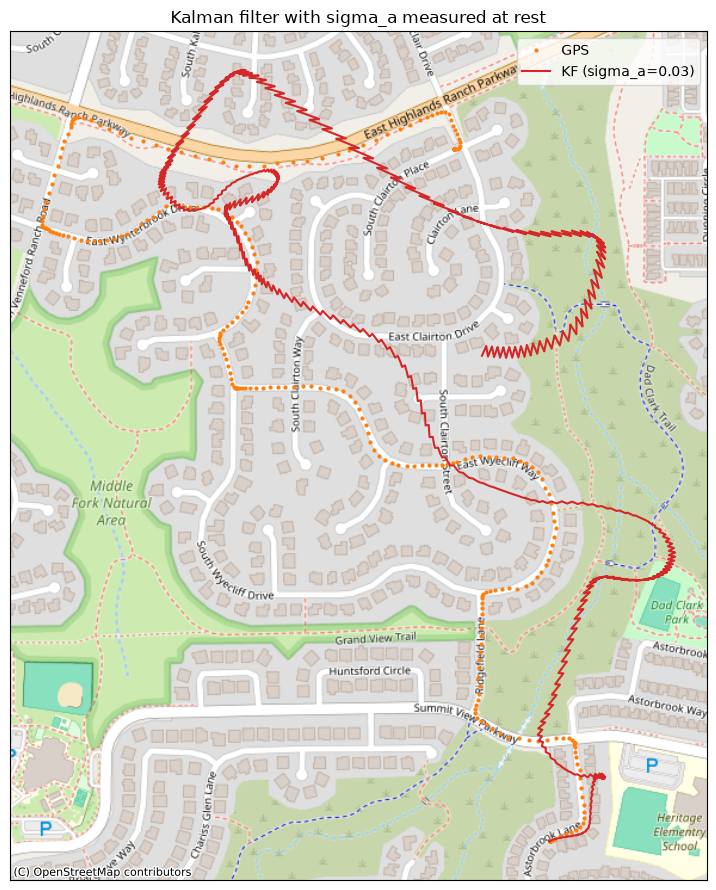

In [16]:
events = make_events(drive, a_east, a_north)
kf_rest = run_kalman_filter(events, SIGMA_A_REST, SIGMA_GPS, start_pos(drive))
innov, nis, v_err = kf_scores(drive, kf_rest)
print(f"sigma_a={SIGMA_A_REST}: innovation RMS {innov:.1f} m, NIS {nis:.0f}, v_err RMS {v_err:.2f} m/s")

utils.plot_tracks(
    [(drive["east"], drive["north"], "GPS", {"color": "tab:orange", "marker": ".", "ms": 4, "ls": "none"}),
     (kf_rest["x"][:, 0], kf_rest["x"][:, 1], f"KF (sigma_a={SIGMA_A_REST})", {"color": "tab:red"})],
    drive["origin"], title="Kalman filter with sigma_a measured at rest", basemap=BASEMAP,
)

Yikes. The filter trusts the accelerometer far too much and mostly ignores the GPS. Two reasons:

* While driving, the acceleration errors are much bigger than the sensor noise at rest: heading errors, hills, vibration, and the board flexing on its mount.
* These errors last for seconds, but the filter assumes each 8 ms sample's error is independent. Independent errors average out quickly, so the filter thinks the IMU's velocity stays accurate for a long time. To compensate, `sigma_a` has to be much larger than the true per-sample noise.

As in the altitude notebook, we sweep `sigma_a` and pick the value that works best:

sigma_a=  0.03: innovation RMS 192.50 m, NIS  8784.20, v_err RMS 12.54 m/s
sigma_a=  0.50: innovation RMS  23.69 m, NIS   113.26, v_err RMS 4.80 m/s
sigma_a=  2.00: innovation RMS   7.47 m, NIS     9.09, v_err RMS 2.58 m/s
sigma_a=  5.00: innovation RMS   3.82 m, NIS     1.85, v_err RMS 1.81 m/s
sigma_a= 10.00: innovation RMS   2.60 m, NIS     0.65, v_err RMS 1.52 m/s
sigma_a= 20.00: innovation RMS   2.07 m, NIS     0.27, v_err RMS 1.42 m/s


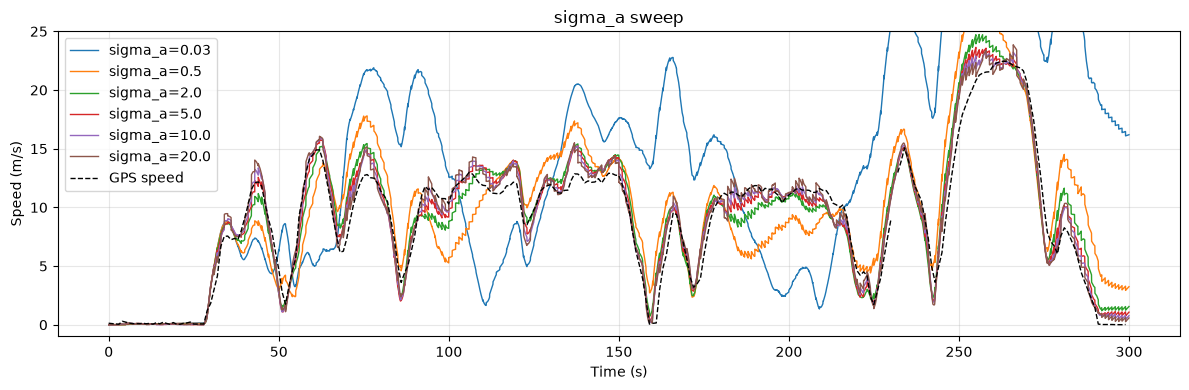

In [17]:
# Try different sigma_a values
sigma_as = [SIGMA_A_REST, 0.5, 2.0, 5.0, 10.0, 20.0]

# Run a filter for each value
v_traces = []
results = []
for sa in sigma_as:
    kf_out = run_kalman_filter(events, sa, SIGMA_GPS, start_pos(drive))
    innov, nis, v_err = kf_scores(drive, kf_out)
    results.append((sa, innov, nis, v_err))
    print(f"sigma_a={sa:6.2f}: innovation RMS {innov:6.2f} m, NIS {nis:8.2f}, v_err RMS {v_err:.2f} m/s")
    speed = np.hypot(kf_out["x"][:, 2], kf_out["x"][:, 3])
    v_traces.append((kf_out["t"], speed, f"sigma_a={sa}"))

# Add reference plot last (so we can see it clearly)
v_traces.append((drive["t_gps"], drive["speed"], "GPS speed", {"color": "k", "ls": "--", "lw": 1}))
utils.plot_traces(v_traces, "Speed (m/s)", title="sigma_a sweep", ylim=(-1, 25))

### GPS noise

You might notice that doubling both `sigma_a` and `sigma_gps` gives exactly the same track: the estimate only depends on their *ratio*. The absolute values only matter for the filter's uncertainty ($P$ and $S$), which is what NIS checks. So we pick the ratio that gives a good track (low innovation and velocity error), then check that NIS is close to 2.

The static recording showed GPS positions wandering slowly by a few metres rather than jumping around from second to second. That slow wander isn't white noise, so the static recording can't give us `sigma_gps` directly. A value of about 2 m, together with the `sigma_a` below, gives a NIS close to 2.

In [28]:
# Choose the sigma_a with low innovation/velocity error and NIS close to 2
SIGMA_A_TUNED = 5.0

## Results

Let's look at the tuned filter on the map. The second plot zooms in on one turn and shows each GPS correction: the open circle is where the filter predicted the car would be (prior), and the line shows where the GPS fix moved the estimate (posterior).

sigma_a=5.0: innovation RMS 3.82 m, NIS 1.85, v_err RMS 1.81 m/s


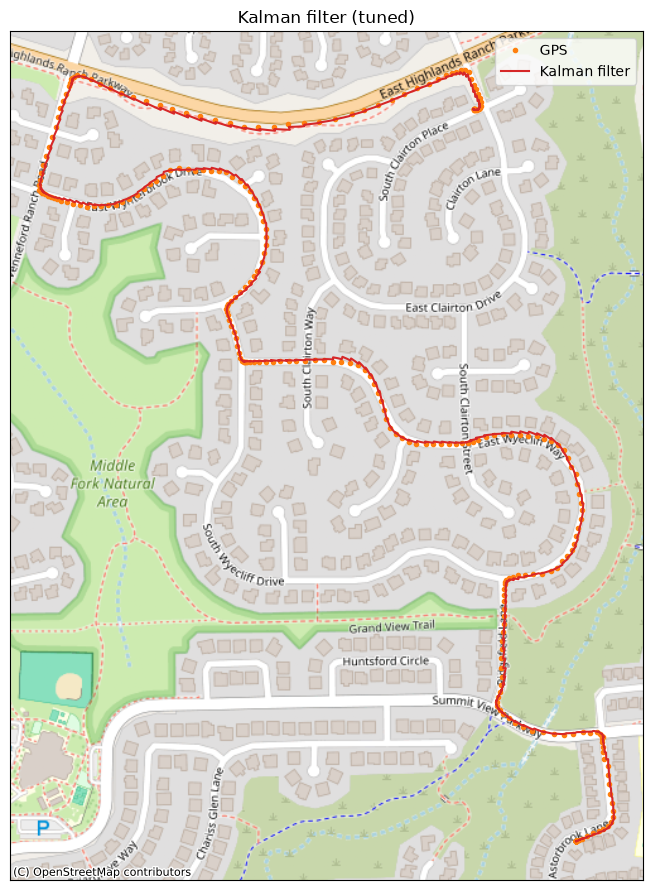

D:\Projects\GitHub\introduction-to-sensor-fusion\venv\Lib\site-packages\contextily\tile.py:680: UserWarning: The inferred zoom level of 20 is not valid for the current tile provider (valid zooms: 0 - 19).
  warnings.warn(msg)


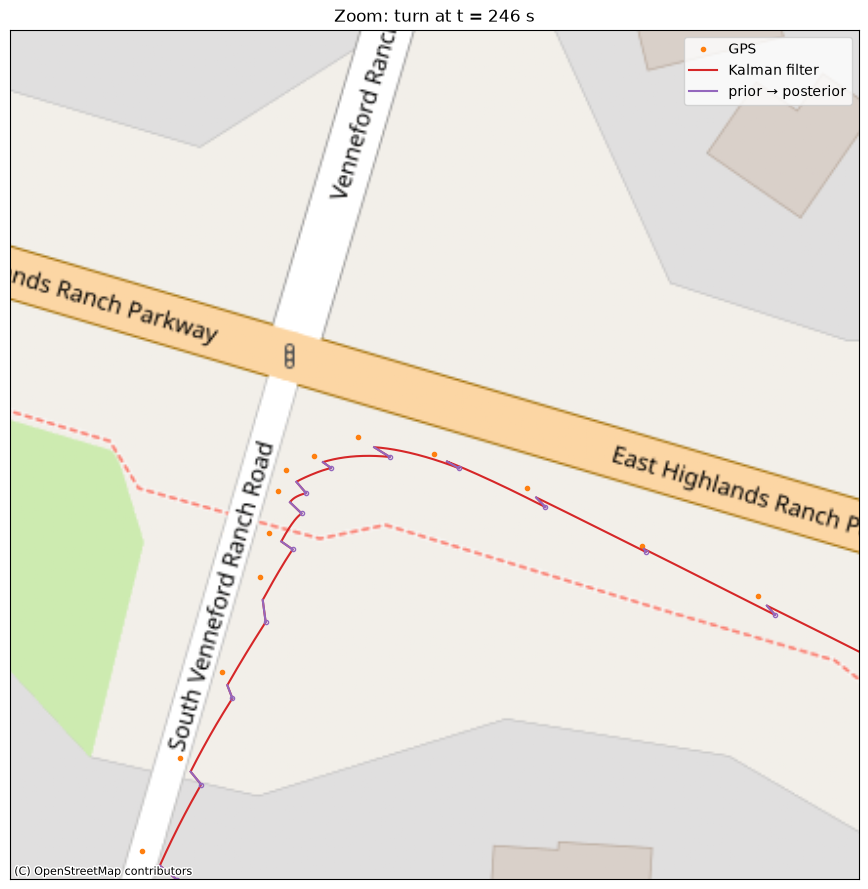

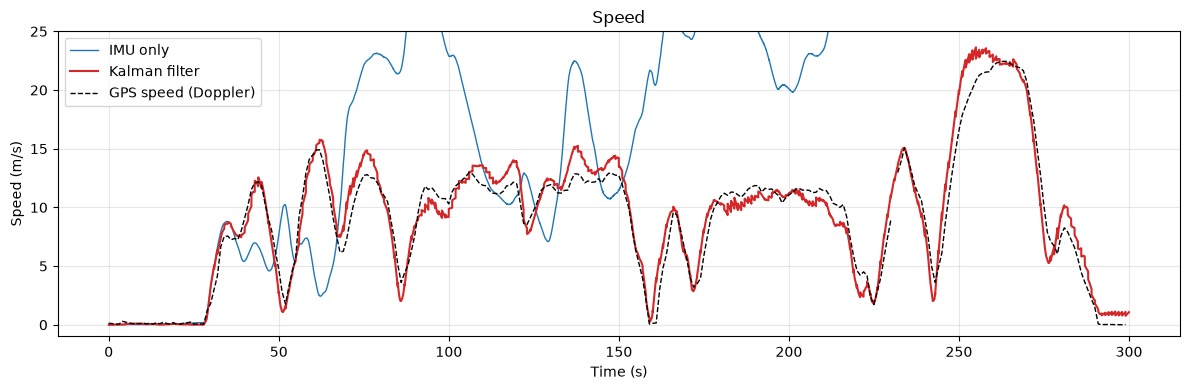

In [29]:
kf_out = run_kalman_filter(events, SIGMA_A_TUNED, SIGMA_GPS, start_pos(drive))
innov, nis, v_err = kf_scores(drive, kf_out)
print(f"sigma_a={SIGMA_A_TUNED}: innovation RMS {innov:.2f} m, NIS {nis:.2f}, v_err RMS {v_err:.2f} m/s")

gps_style = {"color": "tab:orange", "marker": ".", "ms": 6, "ls": "none"}
kf_style = {"color": "tab:red", "lw": 1.5}

utils.plot_tracks(
    [(drive["east"], drive["north"], "GPS", gps_style),
     (kf_out["x"][:, 0], kf_out["x"][:, 1], "Kalman filter", kf_style)],
    drive["origin"], title="Kalman filter (tuned)", basemap=BASEMAP,
)

# Zoom in on the sharpest turn taken at speed (largest change in GPS course)
ok = (drive["speed"] > 8.0) & ~np.isnan(drive["course"])
turn = np.abs(np.gradient(np.unwrap(np.where(ok, drive["course"], 0.0))))
k = np.argmax(np.where(ok, turn, 0.0))
utils.plot_tracks(
    [(drive["east"], drive["north"], "GPS", gps_style),
     (kf_out["x"][:, 0], kf_out["x"][:, 1], "Kalman filter", kf_style)],
    drive["origin"], title=f"Zoom: turn at t = {drive['t_gps'][k]:.0f} s", basemap=BASEMAP,
    zoom=(drive["east"][k], drive["north"][k], 50.0),
    arrows=(kf_out["prior"][:, 0], kf_out["prior"][:, 1],
            kf_out["post"][:, 0], kf_out["post"][:, 1], "prior → posterior"),
)

# Speed: KF vs. GPS Doppler vs. dead reckoning
utils.plot_traces(
    [(drive["t_imu"], np.hypot(v_dr[:, 0], v_dr[:, 1]), "IMU only", {"color": "tab:blue"}),
     (kf_out["t"], np.hypot(kf_out["x"][:, 2], kf_out["x"][:, 3]), "Kalman filter", kf_style),
     (drive["t_gps"], drive["speed"], "GPS speed (Doppler)", {"color": "k", "ls": "--", "lw": 1})],
    "Speed (m/s)", title="Speed", ylim=(-1, 25),
)

## GPS Outages

With a good GPS signal, the filter mostly smooths the track and fills in the gaps between fixes. Where it really earns its keep is when GPS drops out (tunnels, parking garages, tall buildings). Then the IMU has to carry the estimate on its own until GPS comes back.

We simulate an outage by hiding some of the GPS fixes from the filter (including from the heading correction), then compare the filter's estimate to the fixes we withheld.

In [30]:
def find_outage(d, length, after=60.0, min_speed=6.0):
    # Start time of the first window after `after` seconds where the car keeps
    # moving faster than min_speed for the whole window
    for t0 in d["t_gps"][d["t_gps"] > after]:
        win = (d["t_gps"] >= t0) & (d["t_gps"] < t0 + length)
        if np.all(d["speed"][win] > min_speed):
            return t0
    return after


def run_with_outage(d, mount, t0, length, sigma_a, sigma_gps, zero_acc=False,
                    kf_class=KalmanFilter2D, event_fn=None, **kf_args):
    # Run the filter with GPS fixes in [t0, t0 + length) withheld.
    # zero_acc = True ignores the IMU (constant-velocity prediction), for
    # comparison.
    available = ~((d["t_gps"] >= t0) & (d["t_gps"] < t0 + length))
    a_e, a_n, _ = imu_to_east_north(d, mount, gps_available=available)
    if zero_acc:
        a_e, a_n = np.zeros_like(a_e), np.zeros_like(a_n)
    events = (event_fn or make_events)(d, a_e, a_n, available)
    kf_out = run_kalman_filter(events, sigma_a, sigma_gps, start_pos(d), kf_class, **kf_args)

    # Position error at each withheld fix
    hidden = np.where(~available)[0]
    p_e = np.interp(d["t_gps"][hidden], kf_out["t"], kf_out["x"][:, 0])
    p_n = np.interp(d["t_gps"][hidden], kf_out["t"], kf_out["x"][:, 1])
    err = np.hypot(p_e - d["east"][hidden], p_n - d["north"][hidden])
    return kf_out, hidden, err

Simulated outage: 61 s to 71 s
Error at end of outage: with IMU 30.9 m, constant velocity (no IMU) 67.3 m


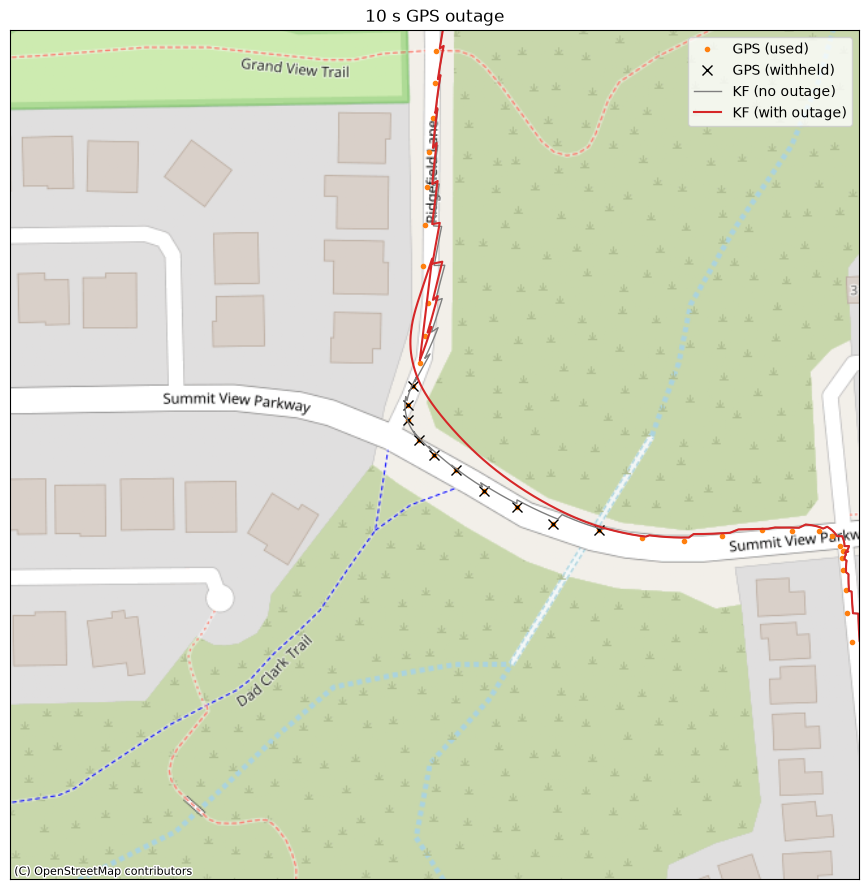

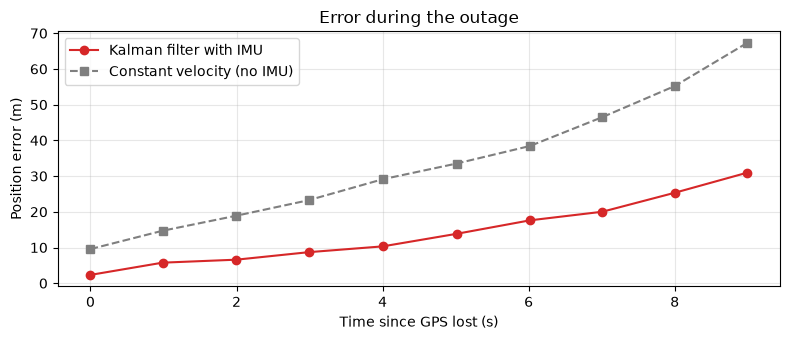

In [31]:
OUTAGE_S = 10.0
t0 = find_outage(drive, OUTAGE_S)
print(f"Simulated outage: {t0:.0f} s to {t0 + OUTAGE_S:.0f} s")

kf_out_o, hidden, err_imu = run_with_outage(drive, mount, t0, OUTAGE_S, SIGMA_A_TUNED, SIGMA_GPS)
_, _, err_cv = run_with_outage(drive, mount, t0, OUTAGE_S, SIGMA_A_TUNED, SIGMA_GPS, zero_acc=True)
print(f"Error at end of outage: with IMU {err_imu[-1]:.1f} m, "
      f"constant velocity (no IMU) {err_cv[-1]:.1f} m")

mid = hidden[len(hidden) // 2]
utils.plot_tracks(
    [(drive["east"], drive["north"], "GPS (used)", gps_style),
     (drive["east"][hidden], drive["north"][hidden], "GPS (withheld)",
      {"color": "k", "marker": "x", "ms": 7, "ls": "none"}),
     (kf_out["x"][:, 0], kf_out["x"][:, 1], "KF (no outage)", {"color": "tab:gray", "lw": 1}),
     (kf_out_o["x"][:, 0], kf_out_o["x"][:, 1], "KF (with outage)", kf_style)],
    drive["origin"], title=f"{OUTAGE_S:.0f} s GPS outage", basemap=BASEMAP,
    zoom=(drive["east"][mid], drive["north"][mid], 150.0),
)

fig, ax = plt.subplots(figsize=(8, 3.5))
t_rel = drive["t_gps"][hidden] - t0
ax.plot(t_rel, err_imu, "o-", color="tab:red", label="Kalman filter with IMU")
ax.plot(t_rel, err_cv, "s--", color="tab:gray", label="Constant velocity (no IMU)")
ax.set_xlabel("Time since GPS lost (s)")
ax.set_ylabel("Position error (m)")
ax.set_title("Error during the outage")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

One outage could be lucky or unlucky, so let's repeat the test every 20 s along the drive and compare the error at the end of each outage. "Constant velocity" means the same filter with the IMU acceleration set to zero: it just keeps going at the last estimated velocity.

In [32]:
def outage_errors(d, mount, length, sigma_a, sigma_gps, every=20.0, start=35.0, **kwargs):
    # Error at the last withheld fix, for outages starting every `every` s
    errs = []
    t0 = start
    while t0 + length < d["t_gps"][-1] - 5.0:
        _, _, err = run_with_outage(d, mount, t0, length, sigma_a, sigma_gps, **kwargs)
        errs.append(err[-1])
        t0 += every
    return np.array(errs)


# Median error at the end of each outage, for a few outage lengths (this takes
# a minute: we rerun the whole drive for every outage)
OUTAGE_LENGTHS = (3.0, 5.0, 10.0)
outage_medians = {"Constant velocity (no IMU)": [], "KF: GPS position": []}
for length in OUTAGE_LENGTHS:
    e_cv = outage_errors(drive, mount, length, SIGMA_A_TUNED, SIGMA_GPS, zero_acc=True)
    e_imu = outage_errors(drive, mount, length, SIGMA_A_TUNED, SIGMA_GPS)
    outage_medians["Constant velocity (no IMU)"].append(np.median(e_cv))
    outage_medians["KF: GPS position"].append(np.median(e_imu))
    print(f"{length:4.0f} s outages ({len(e_imu)}): median error with IMU {np.median(e_imu):5.1f} m, "
          f"constant velocity {np.median(e_cv):5.1f} m")

   3 s outages (13): median error with IMU  10.5 m, constant velocity  21.4 m
   5 s outages (13): median error with IMU  18.1 m, constant velocity  37.3 m
  10 s outages (13): median error with IMU  50.4 m, constant velocity  66.7 m


## Level Up: GPS Velocity

The GPS also measures velocity (from the Doppler shift), and it's quite accurate, around 0.1 to 0.5 m/s. Adding it as a second measurement is easy: the measurement becomes $z = [p_E, p_N, v_E, v_N]^\mathsf{T}$, so

$H = I_4$ (we measure every state directly) and $R = \text{diag}(\sigma_{gps}^2, \sigma_{gps}^2, \sigma_v^2, \sigma_v^2)$

Everything else stays the same. A better velocity estimate going into an outage should mean less drift during it.

In [26]:
# GPS velocity noise std dev (m/s)
SIGMA_V_GPS = 0.5


class KalmanFilter2DVel(KalmanFilter2D):
    # Same filter, but each GPS update also measures East/North velocity

    def __init__(self, sigma_a, sigma_gps, sigma_v=SIGMA_V_GPS, **kwargs):
        super().__init__(sigma_a, sigma_gps, **kwargs)
        self.H = np.eye(4)
        self.D = np.zeros((4, 2))
        self.R = np.diag([sigma_gps**2, sigma_gps**2, sigma_v**2, sigma_v**2])


def make_events_vel(d, a_east, a_north, gps_available=None):
    # Like make_events, but each GPS measurement is [p_E, p_N, v_E, v_N].
    # Fixes with no velocity (missing RMC sentence) are left out.
    if gps_available is None:
        gps_available = np.ones(len(d["t_gps"]), dtype=bool)
    z = np.column_stack([d["east"], d["north"], d["v_east"], d["v_north"]])
    use = gps_available & ~np.isnan(d["v_east"])
    return utils.sorted_streams(
        ("acc", d["t_imu"], np.column_stack([a_east, a_north])),
        ("gps", d["t_gps"][use], z[use]),
    )

In [27]:
events_vel = make_events_vel(drive, a_east, a_north)
kf_vel = run_kalman_filter(events_vel, SIGMA_A_TUNED, SIGMA_GPS, start_pos(drive),
                           kf_class=KalmanFilter2DVel)
innov, nis, _ = kf_scores(drive, kf_vel)
print(f"With GPS velocity: position innovation RMS {innov:.2f} m (NIS now covers 4 measurements: {nis:.2f})")

# Same outage tests as before, now with GPS velocity
outage_medians["KF: GPS position + velocity"] = []
for length in OUTAGE_LENGTHS:
    e_vel = outage_errors(drive, mount, length, SIGMA_A_TUNED, SIGMA_GPS,
                          kf_class=KalmanFilter2DVel, event_fn=make_events_vel)
    outage_medians["KF: GPS position + velocity"].append(np.median(e_vel))
    print(f"{length:4.0f} s outages: median error {np.median(e_vel):5.1f} m")

# Grouped bars: median error at the end of the outage
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.27
colors = ["tab:gray", "tab:red", "tab:green"]
for i, (label, med) in enumerate(outage_medians.items()):
    x = np.arange(len(OUTAGE_LENGTHS)) + (i - 1) * width
    ax.bar(x, med, width, label=label, color=colors[i])
ax.set_xticks(np.arange(len(OUTAGE_LENGTHS)))
ax.set_xticklabels([f"{L:.0f} s" for L in OUTAGE_LENGTHS])
ax.set_xlabel("Outage length")
ax.set_ylabel("Median error at end of outage (m)")
ax.set_title("GPS outages")
ax.grid(alpha=0.3, axis="y")
ax.legend()
fig.tight_layout()
plt.show()

With GPS velocity: position innovation RMS 3.57 m (NIS now covers 4 measurements: 3.04)
   3 s outages: median error   5.4 m
   5 s outages: median error   8.9 m


KeyboardInterrupt: 

## Evaluation

Finally, we run the tuned filter on the drives we did not use for tuning. Each drive gets its own mount calibration (in case the board moved), then we report the same scores and outage errors.

In [ ]:
def eval_drive(path, sigma_a=SIGMA_A_TUNED, sigma_gps=SIGMA_GPS, outage_s=OUTAGE_S):
    if not Path(path).exists():
        print(f"{path} not found, skipping")
        return

    d = load_drive(path)
    m = calibrate_mount(d)
    a_e, a_n, _ = imu_to_east_north(d, m)

    # Full GPS: scores and map
    kf_out = run_kalman_filter(make_events(d, a_e, a_n), sigma_a, sigma_gps, start_pos(d))
    innov, nis, v_err = kf_scores(d, kf_out)
    print(f"  innovation RMS {innov:.2f} m, NIS {nis:.2f}, v_err RMS {v_err:.2f} m/s")

    # Outages
    e_imu = outage_errors(d, m, outage_s, sigma_a, sigma_gps)
    e_cv = outage_errors(d, m, outage_s, sigma_a, sigma_gps, zero_acc=True)
    e_vel = outage_errors(d, m, outage_s, sigma_a, sigma_gps,
                          kf_class=KalmanFilter2DVel, event_fn=make_events_vel)
    print(f"  {outage_s:.0f} s outages ({len(e_imu)}): median error constant velocity "
          f"{np.median(e_cv):.1f} m, KF {np.median(e_imu):.1f} m, KF + GPS velocity {np.median(e_vel):.1f} m")

    utils.plot_tracks(
        [(d["east"], d["north"], "GPS", gps_style),
         (kf_out["x"][:, 0], kf_out["x"][:, 1], "Kalman filter", kf_style)],
        d["origin"], title=f"{d['name']}: Kalman filter", basemap=BASEMAP,
    )

In [ ]:
# Evaluate drive 2
eval_drive(DRIVE_2_PATH)

In [ ]:
# Evaluate drive 3
eval_drive(DRIVE_3_PATH)

In [ ]:
# Evaluate drive 4
eval_drive(DRIVE_4_PATH)

## Takeaways

* The 4-state filter is the 2-state altitude filter twice over: same equations, bigger matrices.
* Getting the sensors to agree was most of the work: GPS fixes arrive ~1 s late, and the IMU's absolute orientation is unreliable in a car (magnetic interference, and acceleration fooling the tilt estimate). Mount calibration plus a GPS-corrected heading got us usable East/North acceleration.
* Errors that last for seconds (heading, hills) aren't the white noise the filter assumes, so `sigma_a` ends up much larger than the noise measured at rest. The innovation and NIS let us tune without a ground truth.
* With good GPS, the filter fills in between fixes. During outages, the IMU roughly halves the drift compared to coasting at constant velocity, and adding GPS Doppler velocity helps even more. But dead reckoning with a consumer IMU still drifts tens of metres in 10 s, so the GPS is what keeps it honest.
* Next step: put heading (and maybe accelerometer bias) into the state, which needs an extended Kalman filter.